In [31]:
import os, json, random, shutil, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (confusion_matrix, classification_report,
                             accuracy_score, precision_recall_fscore_support)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")


# ================== KONFIGURASI ==================
SEED          = 42
IMG_SIZE      = 64      # ukuran resize (modul memberi contoh 48; 64 biasanya lebih akurat)
BATCH_SIZE    = 32
EPOCHS        = 30
LEARNING_RATE = 1e-3
TEST_SIZE     = 0.2     # 80% train : 20% validation/test
MAX_PER_CLASS = None    # isi mis. 1500 jika dataset terlalu besar / ingin lebih cepat
ARTIFACT_DIR  = "artifacts"
# =================================================
os.makedirs(ARTIFACT_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.22.0-rc0 | GPU: []


In [8]:
DATA_DIR = r'C:\Users\user\Videos\Semester 7\OceanicLife Dataset'

In [9]:
# Tampilkan struktur folder (maks. 3 tingkat) beserta jumlah file di tiap folder
def show_tree(root, max_depth=3):
    root = Path(root)
    for dirpath, dirnames, filenames in os.walk(root):
        depth = len(Path(dirpath).relative_to(root).parts)
        if depth > max_depth: 
            dirnames[:] = []
            continue
        print("  " * depth + f"📁 {Path(dirpath).name}  ({len(filenames)} file)")
show_tree(DATA_DIR)

📁 OceanicLife Dataset  (7990 file)


In [10]:
import os
from pathlib import Path
import pandas as pd

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".gif",
           ".JPG", ".JPEG", ".PNG", ".BMP", ".WEBP", ".GIF"}

rows = []
for dirpath, _, filenames in os.walk(DATA_DIR):
    for f in filenames:
        ext = Path(f).suffix
        if ext not in IMG_EXT:
            continue
            
        # Ambil nama folder di mana gambar berada sebagai label
        label = Path(dirpath).name
        
        # Ambil info split jika ada folder train/val/test
        parts = Path(dirpath).relative_to(DATA_DIR).parts
        split = next((SPLITS[p.lower()] for p in parts if p.lower() in SPLITS), "all")

        rows.append({
            "path": str(Path(dirpath) / f),
            "label": label,
            "split_asli": split
        })

df = pd.DataFrame(rows)
print("Total gambar :", len(df))

if not df.empty:
    print("Jumlah kelas :", df["label"].nunique())
    print("Split asli   :", df["split_asli"].value_counts().to_dict())
    print(df.groupby("label").size().sort_values(ascending=False).to_frame("jumlah_gambar"))
else:
    print("Peringatan: Tidak ada gambar yang ditemukan! Periksa kembali lokasi DATA_DIR.")

Total gambar : 7990
Jumlah kelas : 1
Split asli   : {'all': 7990}
                     jumlah_gambar
label                             
OceanicLife Dataset           7990


In [11]:
# 2.1 Inspeksi tiap gambar: ukuran, mode warna, ukuran file, dan deteksi file rusak
def inspect(p):
    try:
        with Image.open(p) as im:
            w, h = im.size; mode = im.mode; im.load()
        return {"path": p, "width": w, "height": h, "mode": mode,
                "size_kb": os.path.getsize(p)/1024, "ok": True}
    except Exception:
        return {"path": p, "width": None, "height": None, "mode": None, "size_kb": None, "ok": False}

with ThreadPoolExecutor(max_workers=16) as ex:
    info = list(tqdm(ex.map(inspect, df["path"]), total=len(df), desc="Inspeksi gambar"))
df = df.merge(pd.DataFrame(info), on="path")

print("Gambar rusak / tidak terbaca:", (~df["ok"]).sum())
df = df[df["ok"]].reset_index(drop=True)
print("Gambar valid:", len(df))

Inspeksi gambar:   0%|          | 0/7990 [00:00<?, ?it/s]

Gambar rusak / tidak terbaca: 8
Gambar valid: 7982


## Langkah 1b — Pelabelan Otomatis (Pseudo-label dengan CLIP)
Dataset ini **tidak punya subfolder per kelas** (7.990 gambar dalam satu folder), sehingga label asli tidak tersedia.
Karena itu label dibuat otomatis dengan **CLIP zero-shot**, lalu CNN dilatih dari label tersebut.
> Di laporan, sebutkan bahwa label adalah **pseudo-label (hasil CLIP)**, bukan ground truth. Akurasi CNN = kesesuaian CNN dengan label CLIP.

In [12]:
# Jalankan sekali saja. Setelah terpasang, boleh di-comment.
%pip install -q torch transformers

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
import torch
from transformers import CLIPModel, CLIPProcessor

# ===== Konfigurasi pseudo-label =====
CLIP_MODEL     = "openai/clip-vit-base-patch32"
CLIP_BATCH     = 32
CONF_THRESHOLD = 0.50     # buang gambar yang keyakinan CLIP-nya di bawah ini (0 = pakai semua)
LABEL_CACHE    = f"{ARTIFACT_DIR}/pseudo_labels.csv"

# Tiap kelas boleh punya beberapa deskripsi; skor kelas = jumlah probabilitas deskripsinya
CLASS_PROMPTS = {
    "fish":        ["a photo of a fish", "an underwater photo of a fish", "a school of fish"],
    "coral":       ["a photo of coral", "an underwater photo of a coral reef"],
    "shark":       ["a photo of a shark", "an underwater photo of a shark"],
    "octopus":     ["a photo of an octopus", "a photo of a squid or cuttlefish"],
    "crustacean":  ["a photo of a crab", "a photo of a lobster", "a photo of a shrimp"],
    "seaweed":     ["a photo of seaweed", "an underwater photo of kelp"],
    "sponge":      ["a photo of a sea sponge"],
    "other marine organism": ["a photo of a jellyfish", "a photo of a starfish", "a photo of a sea turtle",
                              "a photo of a dolphin or a whale", "a photo of a sea urchin", "a photo of a sea anemone"],
}
clip_classes = list(CLASS_PROMPTS)
prompts, prompt_to_class = [], []
for ci, (cname, ps) in enumerate(CLASS_PROMPTS.items()):
    for p in ps: prompts.append(p); prompt_to_class.append(ci)
prompt_to_class = torch.tensor(prompt_to_class)

def open_fast(p):
    im = Image.open(p)
    try: im.draft("RGB", (448, 448))      # percepat decoding JPEG besar
    except Exception: pass
    return im.convert("RGB")

if os.path.exists(LABEL_CACHE):
    pl = pd.read_csv(LABEL_CACHE)
    print("Memakai cache pseudo-label:", LABEL_CACHE, len(pl))
else:
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print("Device CLIP:", device, "(di CPU kira-kira 10-25 menit untuk ~8 ribu gambar)")
    clip = CLIPModel.from_pretrained(CLIP_MODEL).to(device).eval()
    proc = CLIPProcessor.from_pretrained(CLIP_MODEL)

    paths = df["path"].tolist(); out_lab, out_conf = [], []
    with ThreadPoolExecutor(max_workers=8) as ex, torch.no_grad():
        for i in tqdm(range(0, len(paths), CLIP_BATCH), desc="CLIP pseudo-label"):
            imgs = list(ex.map(open_fast, paths[i:i+CLIP_BATCH]))
            inp = proc(text=prompts, images=imgs, return_tensors="pt", padding=True).to(device)
            probs = clip(**inp).logits_per_image.softmax(dim=-1).cpu()
            cls_probs = torch.zeros(probs.shape[0], len(clip_classes)).index_add_(1, prompt_to_class, probs)
            conf, idx = cls_probs.max(dim=1)
            out_lab += [clip_classes[j] for j in idx.tolist()]; out_conf += conf.tolist()
    pl = pd.DataFrame({"path": paths, "label_clip": out_lab, "conf_clip": out_conf})
    pl.to_csv(LABEL_CACHE, index=False)
    print("Pseudo-label disimpan:", LABEL_CACHE)

Device CLIP: cpu (di CPU kira-kira 10-25 menit untuk ~8 ribu gambar)


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

...

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP pseudo-label:   0%|          | 0/250 [00:00<?, ?it/s]

Error in sys.excepthook:
Traceback (most recent call last):
  File "c:\Users\user\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\ipykernel\iostream.py", line 217, in _event_pipe
    event_pipe = self._local.event_pipe
                 ^^^^^^^^^^^^^^^^^^^^^^
AttributeError: '_thread._local' object has no attribute 'event_pipe'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\user\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\interactiveshell.py", line 2166, in excepthook
    self.showtraceback((etype, value, tb), tb_offset=0)
    ~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\user\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\interactiveshell.py", line 2291, in showtraceback
    self._showtraceback(etype, value, stb)
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^
  File "c:\Users\user\AppData\Local\Python\pythoncore-3.14-64\Lib\site-pack

Pseudo-label disimpan: artifacts/pseudo_labels.csv


In [14]:
# Terapkan pseudo-label ke dataframe utama
df = df.drop(columns=["label"]).merge(pl.rename(columns={"label_clip": "label"}), on="path")
print(f"Total sebelum filter : {len(df)}")
low = (df["conf_clip"] < CONF_THRESHOLD).sum()
df = df[df["conf_clip"] >= CONF_THRESHOLD].reset_index(drop=True)
print(f"Dibuang (keyakinan CLIP < {CONF_THRESHOLD}): {low} | Dipakai: {len(df)}")
print("Rata-rata keyakinan CLIP:", round(df["conf_clip"].mean(), 3))
display(df["label"].value_counts().to_frame("jumlah_gambar"))

# Pengaman: klasifikasi butuh minimal 2 kelas dan tiap kelas cukup data untuk split 80/20
n_cls = df["label"].nunique()
assert n_cls >= 2, "Hanya 1 kelas terdeteksi -> evaluasi 100% tidak valid. Periksa pelabelan."
tiny = df["label"].value_counts()[lambda s: s < 10]
if len(tiny):
    print("PERINGATAN: kelas dengan <10 gambar (pertimbangkan digabung ke 'other marine organism'):", tiny.to_dict())

Total sebelum filter : 7982
Dibuang (keyakinan CLIP < 0.5): 1287 | Dipakai: 6695
Rata-rata keyakinan CLIP: 0.826


,jumlah_gambar
label,
fish,2057
other marine organism,1773
crustacean,716
coral,668
octopus,637
shark,596
sponge,195
seaweed,53


Isi kolom label_manual di: artifacts/cek_manual_100.csv (pakai nama kelas yang sama)


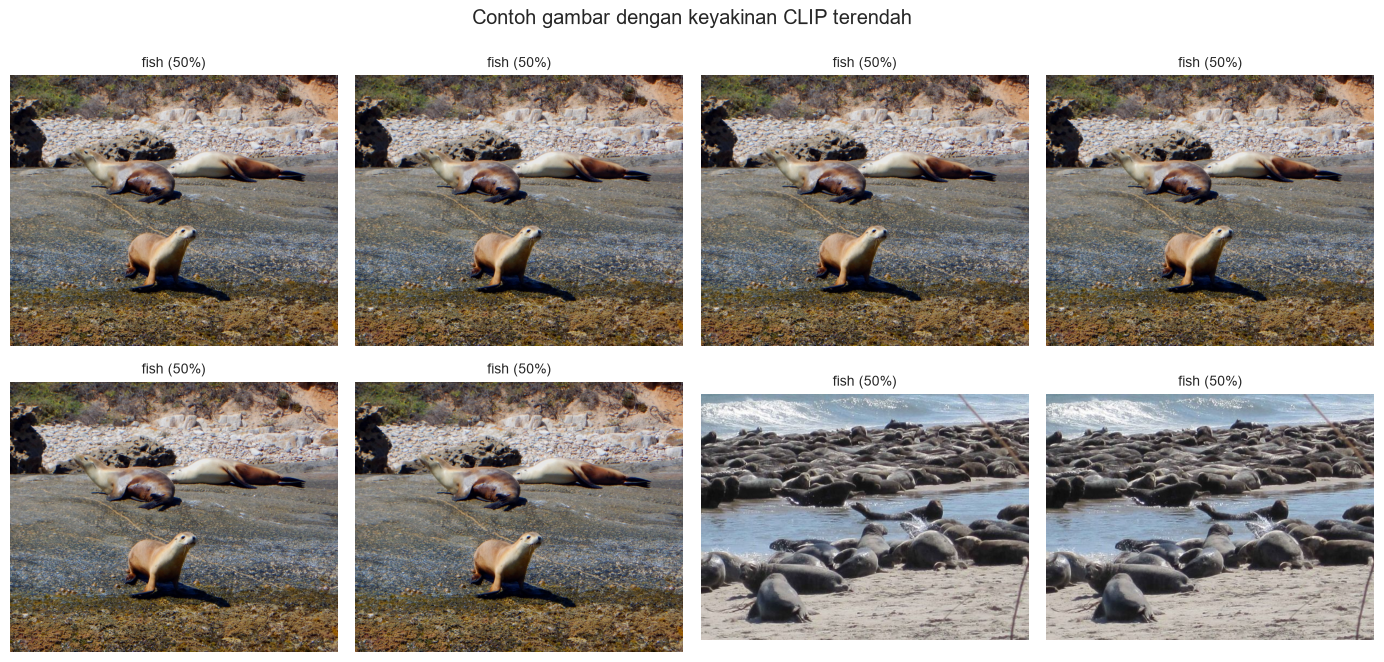

In [15]:
# Validasi manual: ambil 100 gambar acak, isi kolom label_manual di CSV, lalu hitung akurasi label CLIP
check = df.sample(min(100, len(df)), random_state=SEED)[["path", "label", "conf_clip"]].rename(columns={"label": "label_clip"})
check["label_manual"] = ""
check.to_csv(f"{ARTIFACT_DIR}/cek_manual_100.csv", index=False)
print("Isi kolom label_manual di:", f"{ARTIFACT_DIR}/cek_manual_100.csv", "(pakai nama kelas yang sama)")

# Tampilkan contoh gambar dengan keyakinan CLIP terendah untuk dicek visual
low_conf = df.nsmallest(8, "conf_clip")
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for a, (_, r) in zip(axes.ravel(), low_conf.iterrows()):
    a.imshow(open_fast(r["path"])); a.axis("off"); a.set_title(f"{r['label']} ({r['conf_clip']:.0%})", fontsize=10)
plt.suptitle("Contoh gambar dengan keyakinan CLIP terendah"); plt.tight_layout(); plt.show()

In [16]:
# (Jalankan SETELAH label_manual terisi) Estimasi akurasi pseudo-label
chk = pd.read_csv(f"{ARTIFACT_DIR}/cek_manual_100.csv").dropna(subset=["label_manual"])
chk = chk[chk["label_manual"].astype(str).str.strip() != ""]
if len(chk):
    label_acc = (chk["label_clip"].str.strip().str.lower() == chk["label_manual"].str.strip().str.lower()).mean()
    print(f"Sampel dicek: {len(chk)} | Estimasi akurasi pseudo-label: {label_acc:.1%}")
else:
    print("label_manual belum terisi.")

label_manual belum terisi.


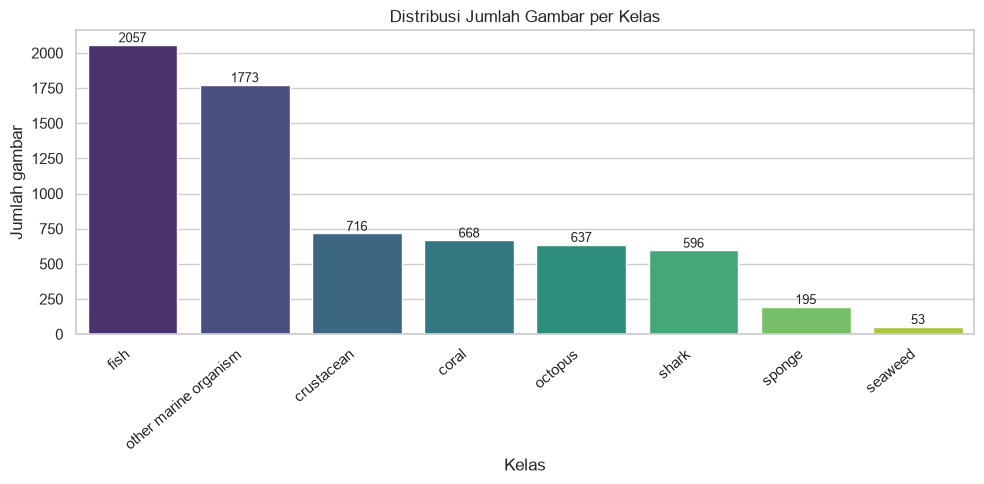

Kelas terbanyak : fish (2057)
Kelas tersedikit: seaweed (53)
Rasio imbalance : 38.81x -> TIDAK seimbang (perlu class weight / augmentasi)


In [17]:
# 2.2 Distribusi jumlah gambar per kelas + cek class imbalance
dist = df["label"].value_counts()
imb_ratio = dist.max() / dist.min()

plt.figure(figsize=(10,5))
ax = sns.barplot(x=dist.index, y=dist.values, palette="viridis")
for i, v in enumerate(dist.values): ax.text(i, v, str(v), ha="center", va="bottom", fontsize=9)
plt.title("Distribusi Jumlah Gambar per Kelas"); plt.xlabel("Kelas"); plt.ylabel("Jumlah gambar")
plt.xticks(rotation=40, ha="right"); plt.tight_layout(); plt.show()

print(f"Kelas terbanyak : {dist.idxmax()} ({dist.max()})")
print(f"Kelas tersedikit: {dist.idxmin()} ({dist.min()})")
print(f"Rasio imbalance : {imb_ratio:.2f}x ->", 
      "TIDAK seimbang (perlu class weight / augmentasi)" if imb_ratio > 1.5 else "relatif seimbang")

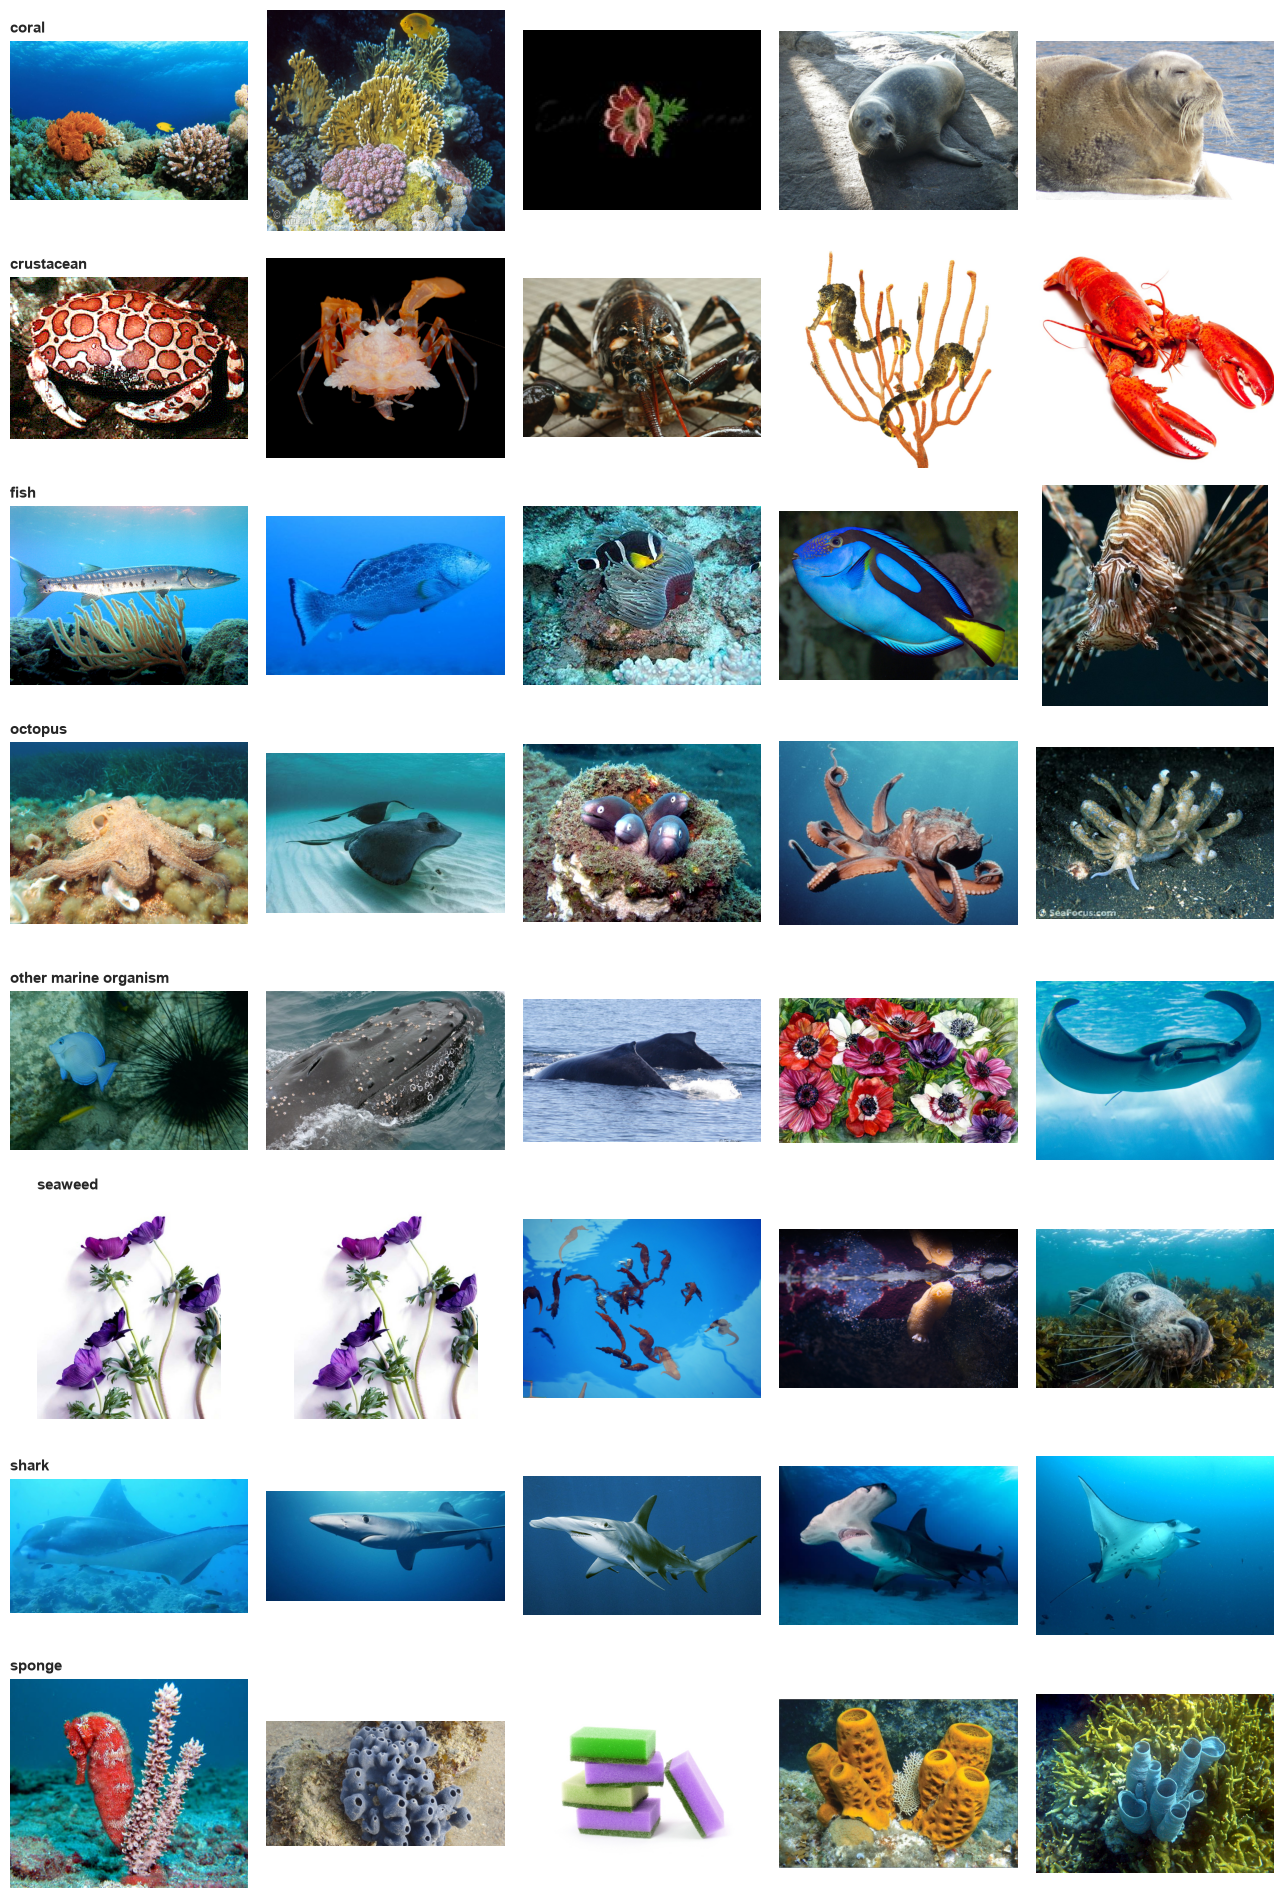

In [18]:
# 2.3 Contoh visual tiap kelas
classes_eda = sorted(df["label"].unique())
n_show = 5
fig, axes = plt.subplots(len(classes_eda), n_show, figsize=(2.6*n_show, 2.4*len(classes_eda)))
axes = np.atleast_2d(axes)
for r, c in enumerate(classes_eda):
    samples = df[df["label"]==c].sample(min(n_show, (df["label"]==c).sum()), random_state=SEED)["path"].tolist()
    for k in range(n_show):
        axes[r,k].axis("off")
        if k < len(samples):
            axes[r,k].imshow(Image.open(samples[k]).convert("RGB"))
        if k == 0: axes[r,k].set_title(c, loc="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

Mode warna:
 mode
RGB     6570
P         58
RGBA      58
L          9
Name: count, dtype: int64 

        width  height  size_kb
count  6695.0  6695.0   6695.0
mean   1216.8   887.6    368.9
std     855.8   637.4    737.4
min     125.0   113.0      1.8
25%     640.0   478.0     62.4
50%    1000.0   720.0    147.3
75%    1571.0  1064.0    355.7
max    6144.0  4378.0   8785.6


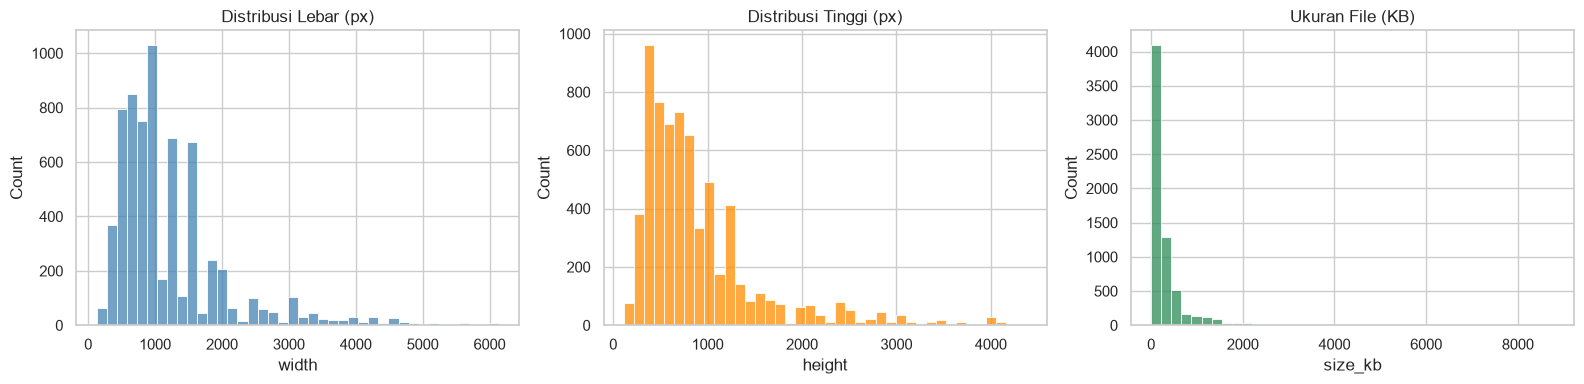

Gambar lebih kecil dari 64px: 0 (0.0%) -> kualitas turun saat di-upscale
Ukuran unik: 586 -> ukuran tidak seragam, perlu resize


In [19]:
# 2.4 Ukuran gambar, format warna, dan kualitas
print("Mode warna:\n", df["mode"].value_counts(), "\n")
print(df[["width","height","size_kb"]].describe().round(1))

fig, ax = plt.subplots(1, 3, figsize=(16,4))
sns.histplot(df["width"],  bins=40, ax=ax[0], color="steelblue"); ax[0].set_title("Distribusi Lebar (px)")
sns.histplot(df["height"], bins=40, ax=ax[1], color="darkorange"); ax[1].set_title("Distribusi Tinggi (px)")
sns.histplot(df["size_kb"], bins=40, ax=ax[2], color="seagreen"); ax[2].set_title("Ukuran File (KB)")
plt.tight_layout(); plt.show()

small = ((df["width"] < IMG_SIZE) | (df["height"] < IMG_SIZE)).sum()
print(f"Gambar lebih kecil dari {IMG_SIZE}px: {small} ({small/len(df):.1%}) -> kualitas turun saat di-upscale")
print(f"Ukuran unik: {df[['width','height']].drop_duplicates().shape[0]} -> ukuran tidak seragam, perlu resize")

In [20]:
# 3.1 (opsional) batasi jumlah gambar per kelas agar training lebih cepat
if MAX_PER_CLASS:
    df = (df.groupby("label", group_keys=False)
            .apply(lambda g: g.sample(min(len(g), MAX_PER_CLASS), random_state=SEED))
            .reset_index(drop=True))

# 3.2 Encoding label -> angka
le = LabelEncoder()
df["y"] = le.fit_transform(df["label"])
class_names = list(le.classes_)
NUM_CLASSES = len(class_names)
print("Mapping label:", dict(enumerate(class_names)))

# 3.3 Split 80% train : 20% validation/test (stratified agar proporsi kelas terjaga)
train_df, val_df = train_test_split(df, test_size=TEST_SIZE, stratify=df["y"], random_state=SEED)
print(f"Train: {len(train_df)} | Validation/Test: {len(val_df)}")

# 3.4 Resize ke IMG_SIZE x IMG_SIZE (RGB) -> array uint8
def load_img(p):
    with Image.open(p) as im:
        return np.asarray(im.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR), dtype=np.uint8)

def load_many(paths):
    with ThreadPoolExecutor(max_workers=16) as ex:
        return np.stack(list(tqdm(ex.map(load_img, paths), total=len(paths))))

X_train = load_many(train_df["path"]); y_train = train_df["y"].values
X_val   = load_many(val_df["path"]);   y_val   = val_df["y"].values
print("X_train:", X_train.shape, "| X_val:", X_val.shape)

Mapping label: {0: 'coral', 1: 'crustacean', 2: 'fish', 3: 'octopus', 4: 'other marine organism', 5: 'seaweed', 6: 'shark', 7: 'sponge'}
Train: 5356 | Validation/Test: 1339


  0%|          | 0/5356 [00:00<?, ?it/s]

  0%|          | 0/1339 [00:00<?, ?it/s]

X_train: (5356, 64, 64, 3) | X_val: (1339, 64, 64, 3)


Class weight: {'coral': 1.25, 'crustacean': 1.17, 'fish': 0.41, 'octopus': 1.31, 'other marine organism': 0.47, 'seaweed': 15.94, 'shark': 1.4, 'sponge': 4.29}


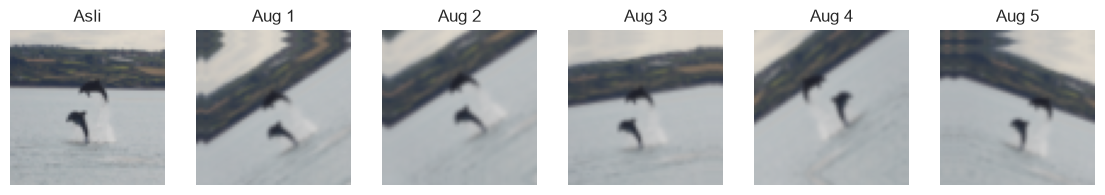

In [21]:
# 3.5 Normalisasi piksel ke rentang 0-1 (dilakukan di pipeline tf.data agar hemat memori)
def normalize(x, y):
    return tf.cast(x, tf.float32) / 255.0, y

AUTOTUNE = tf.data.AUTOTUNE
train_ds = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
            .shuffle(len(X_train), seed=SEED).batch(BATCH_SIZE).map(normalize, AUTOTUNE).prefetch(AUTOTUNE))
val_ds   = (tf.data.Dataset.from_tensor_slices((X_val, y_val))
            .batch(BATCH_SIZE).map(normalize, AUTOTUNE).prefetch(AUTOTUNE))

# 3.6 Class weight untuk menangani class imbalance
cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train)
class_weight = {i: float(w) for i, w in enumerate(cw)}
print("Class weight:", {class_names[i]: round(w,2) for i, w in class_weight.items()})

# 3.7 Data augmentation (rotasi, flip, zoom, shift) -> dipakai sebagai layer di model
augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
], name="augmentation")

# Pratinjau hasil augmentasi
img0 = (X_train[0:1] / 255.0).astype("float32")
fig, ax = plt.subplots(1, 6, figsize=(14,2.6))
ax[0].imshow(img0[0]); ax[0].set_title("Asli"); ax[0].axis("off")
for i in range(1, 6):
    ax[i].imshow(np.clip(augmentation(img0, training=True)[0].numpy(), 0, 1)); ax[i].set_title(f"Aug {i}"); ax[i].axis("off")
plt.show()

In [22]:
def build_model(num_classes, img_size=IMG_SIZE, lr=LEARNING_RATE):
    inp = layers.Input((img_size, img_size, 3))
    x = augmentation(inp)

    for f in (32, 64):
        x = layers.Conv2D(f, 3, padding="same", activation="relu")(x); x = layers.BatchNormalization()(x)
        x = layers.Conv2D(f, 3, padding="same", activation="relu")(x); x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x); x = layers.Dropout(0.25)(x)

    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x); x = layers.BatchNormalization()(x)
    x = layers.Conv2D(128, 3, padding="same", activation="relu", name="last_conv")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x); x = layers.Dropout(0.25)(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(num_classes, activation="softmax")(x)

    m = models.Model(inp, out, name="oceanic_cnn")
    m.compile(optimizer=optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

model = build_model(NUM_CLASSES)
model.summary()

Model: "oceanic_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv (Conv2D)              │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 323,880 (1.24 MB)

 Trainable params: 322,984 (1.23 MB)

 Non-trainable params: 896 (3.50 KB)

In [23]:
MODEL_PATH = f"{ARTIFACT_DIR}/oceanic_cnn.keras"
cbs = [
    callbacks.EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5, verbose=1),
    callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_loss", save_best_only=True),
]

history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                    class_weight=class_weight, callbacks=cbs)

model.save(MODEL_PATH)   # simpan model final (bobot terbaik) untuk Streamlit
print("Model disimpan:", MODEL_PATH)

Epoch 1/30
168/168 ━━━━━━━━━━━━━━━━━━━━ 50s 283ms/step - accuracy: 0.2074 - loss: 2.0663 - val_accuracy: 0.1568 - val_loss: 2.5974 - learning_rate: 0.0010
Epoch 2/30
168/168 ━━━━━━━━━━━━━━━━━━━━ 48s 287ms/step - accuracy: 0.2058 - loss: 1.9004 - val_accuracy: 0.1479 - val_loss: 2.0572 - learning_rate: 0.0010
Epoch 3/30
168/168 ━━━━━━━━━━━━━━━━━━━━ 47s 280ms/step - accuracy: 0.2298 - loss: 1.8167 - val_accuracy: 0.2860 - val_loss: 1.7926 - learning_rate: 0.0010
Epoch 4/30
168/168 ━━━━━━━━━━━━━━━━━━━━ 49s 289ms/step - accuracy: 0.2478 - loss: 1.7018 - val_accuracy: 0.2636 - val_loss: 1.9008 - learning_rate: 0.0010
Epoch 5/30
168/168 ━━━━━━━━━━━━━━━━━━━━ 48s 284ms/step - accuracy: 0.2767 - loss: 1.6082 - val_accuracy: 0.2226 - val_loss: 1.8236 - learning_rate: 0.0010
Epoch 6/30
168/168 ━━━━━━━━━━━━━━━━━━━━ 46s 274ms/step - accuracy: 0.3068 - loss: 1.5248 - val_accuracy: 0.2838 - val_loss: 1.7800 - learning_rate: 0.0010
Epoch 7/30
168/168 ━━━━━━━━━━━━━━━━━━━━ 51s 303ms/step - accuracy: 0.3

In [24]:
val_probs = model.predict(val_ds, verbose=0)
y_pred = val_probs.argmax(axis=1)

acc = accuracy_score(y_val, y_pred)
p_m, r_m, f_m, _ = precision_recall_fscore_support(y_val, y_pred, average="macro",    zero_division=0)
p_w, r_w, f_w, _ = precision_recall_fscore_support(y_val, y_pred, average="weighted", zero_division=0)

summary_tbl = pd.DataFrame({
    "Accuracy":  [acc, acc],
    "Precision": [p_m, p_w],
    "Recall":    [r_m, r_w],
    "F1-Score":  [f_m, f_w],
}, index=["Macro avg", "Weighted avg"]).round(4)
display(summary_tbl)

report = classification_report(y_val, y_pred, target_names=class_names, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).T.round(4)
display(report_df)

,Accuracy,Precision,Recall,F1-Score
Macro avg,0.658,0.6291,0.7908,0.6718
Weighted avg,0.658,0.6915,0.6580,0.6488


,precision,recall,f1-score,support
coral,0.5667,0.8881,0.6919,134.000
crustacean,0.7235,0.8601,0.7859,143.000
fish,0.7195,0.5742,0.6387,411.000
octopus,0.4798,0.7480,0.5846,127.000
other marine organism,0.7744,0.4254,0.5491,355.000
seaweed,0.3667,1.0000,0.5366,11.000
shark,0.7025,0.9328,0.8014,119.000
sponge,0.7000,0.8974,0.7865,39.000
accuracy,0.6580,0.6580,0.6580,0.658
macro avg,0.6291,0.7908,0.6718,1339.000


In [25]:
# Interpretasi otomatis
per_class = report_df.loc[class_names]
best, worst = per_class["f1-score"].idxmax(), per_class["f1-score"].idxmin()
print(f"• Akurasi keseluruhan: {acc:.2%} -> " + ("model mengenali kelas dengan baik." if acc >= 0.8 else "masih perlu perbaikan (lebih banyak epoch/data, resolusi lebih besar, atau transfer learning)."))
print(f"• F1 macro {f_m:.3f} vs weighted {f_w:.3f} -> " + ("selisih kecil: performa merata antar kelas." if abs(f_m-f_w) < 0.03 else "selisih terlihat: kelas minoritas cenderung lebih sulit."))
print(f"• Kelas paling mudah dikenali : {best} (F1={per_class.loc[best,'f1-score']:.3f})")
print(f"• Kelas paling sulit dikenali : {worst} (F1={per_class.loc[worst,'f1-score']:.3f}, support={int(per_class.loc[worst,'support'])})")

• Akurasi keseluruhan: 65.80% -> masih perlu perbaikan (lebih banyak epoch/data, resolusi lebih besar, atau transfer learning).
• F1 macro 0.672 vs weighted 0.649 -> selisih kecil: performa merata antar kelas.
• Kelas paling mudah dikenali : shark (F1=0.801)
• Kelas paling sulit dikenali : seaweed (F1=0.537, support=11)


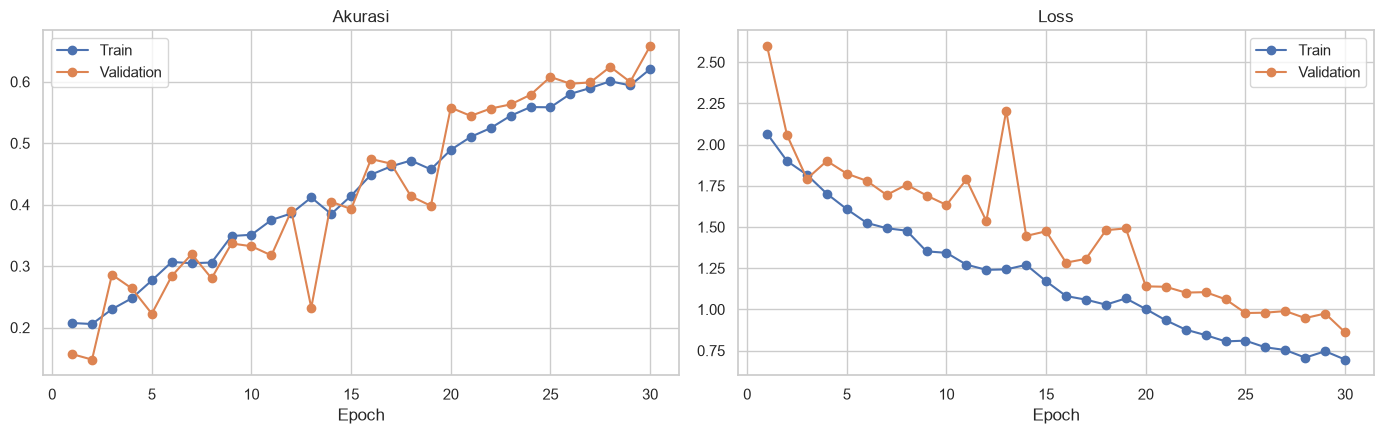

Selisih akurasi train-val di epoch terakhir: -0.037 -> generalisasi cukup baik


In [26]:
# 6.1 Grafik akurasi & loss selama training
hist = history.history
ep = range(1, len(hist["loss"])+1)
fig, ax = plt.subplots(1, 2, figsize=(14,4.5))
ax[0].plot(ep, hist["accuracy"], "o-", label="Train"); ax[0].plot(ep, hist["val_accuracy"], "o-", label="Validation")
ax[0].set_title("Akurasi"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(ep, hist["loss"], "o-", label="Train"); ax[1].plot(ep, hist["val_loss"], "o-", label="Validation")
ax[1].set_title("Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

gap = hist["accuracy"][-1] - hist["val_accuracy"][-1]
print(f"Selisih akurasi train-val di epoch terakhir: {gap:.3f} ->", "indikasi overfitting" if gap > 0.1 else "generalisasi cukup baik")

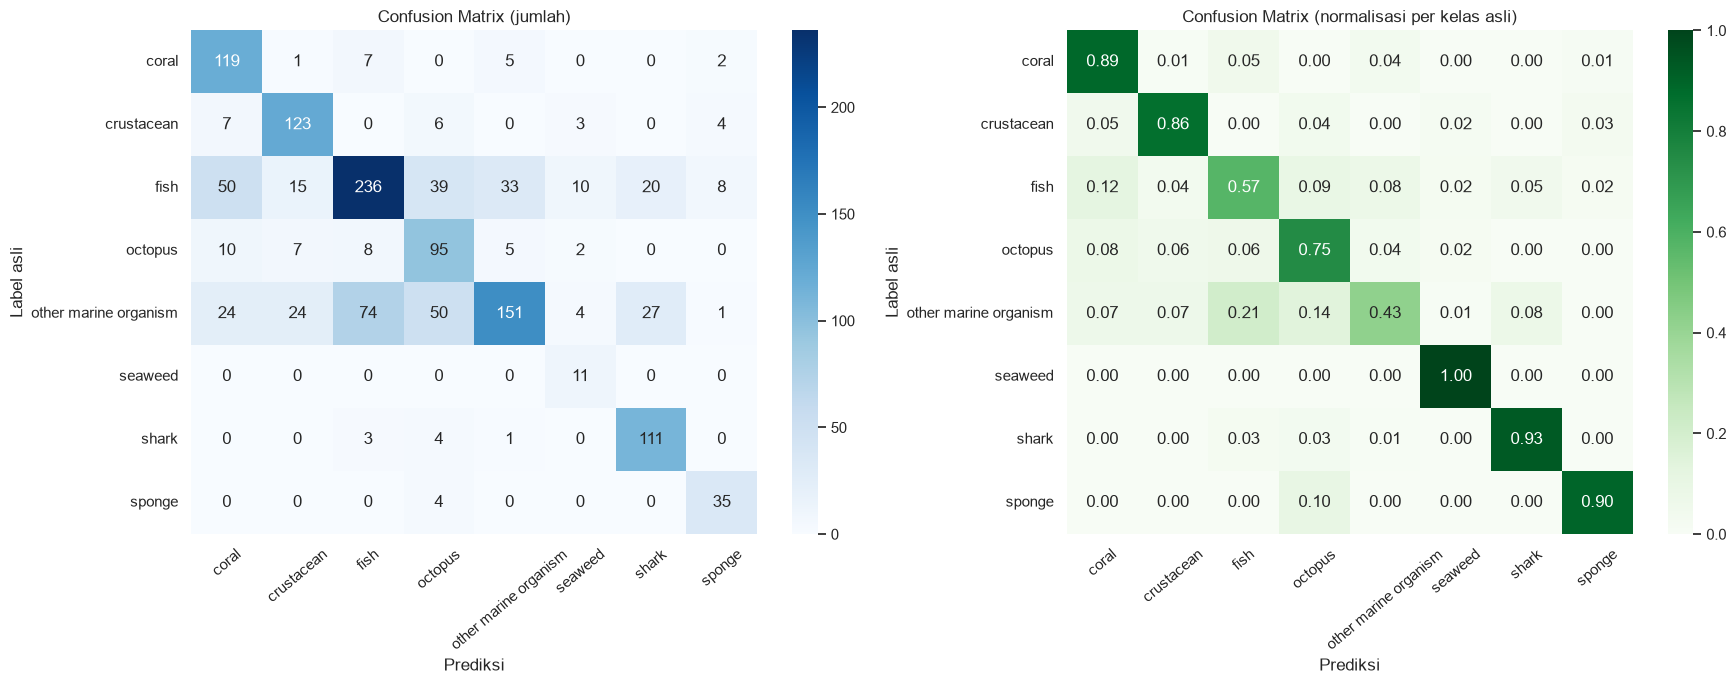

Kesalahan terbanyak: 'other marine organism' diprediksi sebagai 'fish' sebanyak 74 gambar.


In [27]:
# 6.2 Confusion matrix (jumlah & dinormalisasi per baris)
cm = confusion_matrix(y_val, y_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(1, 2, figsize=(18,7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=ax[0])
ax[0].set_title("Confusion Matrix (jumlah)")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Greens", xticklabels=class_names, yticklabels=class_names, ax=ax[1])
ax[1].set_title("Confusion Matrix (normalisasi per kelas asli)")
for a in ax: a.set_xlabel("Prediksi"); a.set_ylabel("Label asli"); a.tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
i, j = np.unravel_index(off.argmax(), off.shape)
print(f"Kesalahan terbanyak: '{class_names[i]}' diprediksi sebagai '{class_names[j]}' sebanyak {off[i,j]} gambar.")

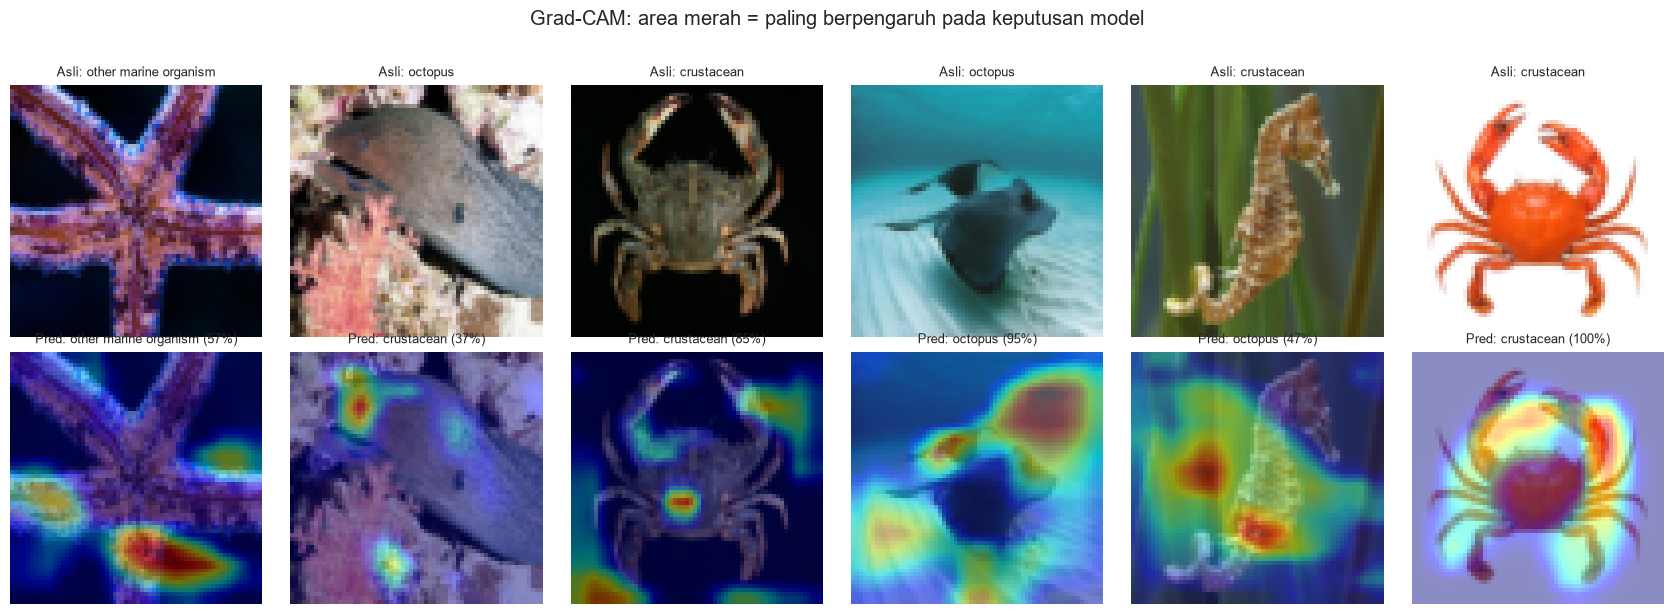

In [28]:
# 6.3 "Feature importance" citra dengan Grad-CAM: area gambar yang paling memengaruhi keputusan model
def grad_cam(img_batch, model, layer_name="last_conv"):
    gm = tf.keras.Model(model.inputs, [model.get_layer(layer_name).output, model.output])
    with tf.GradientTape() as tape:
        conv_out, preds = gm(tf.convert_to_tensor(img_batch))
        cls = int(tf.argmax(preds[0]))
        score = preds[:, cls]
    grads = tape.gradient(score, conv_out)
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))
    heat = tf.nn.relu(tf.reduce_sum(conv_out[0] * weights, axis=-1))
    heat = (heat / (tf.reduce_max(heat) + 1e-8)).numpy()
    return heat, cls, preds[0].numpy()

def overlay(img, heat, alpha=0.45):
    h = tf.image.resize(heat[..., None], img.shape[:2]).numpy()[..., 0]
    colored = plt.cm.jet(h)[..., :3]
    return np.clip((1-alpha)*img + alpha*colored, 0, 1)

idx = np.random.RandomState(SEED).choice(len(X_val), 6, replace=False)
fig, ax = plt.subplots(2, 6, figsize=(17,6))
for k, i in enumerate(idx):
    img = X_val[i] / 255.0
    heat, cls, p = grad_cam(img[None].astype("float32"), model)
    ax[0,k].imshow(img); ax[0,k].set_title(f"Asli: {class_names[y_val[i]]}", fontsize=9); ax[0,k].axis("off")
    ax[1,k].imshow(overlay(img, heat)); ax[1,k].set_title(f"Pred: {class_names[cls]} ({p[cls]:.0%})", fontsize=9); ax[1,k].axis("off")
plt.suptitle("Grad-CAM: area merah = paling berpengaruh pada keputusan model", y=1.02)
plt.tight_layout(); plt.show()

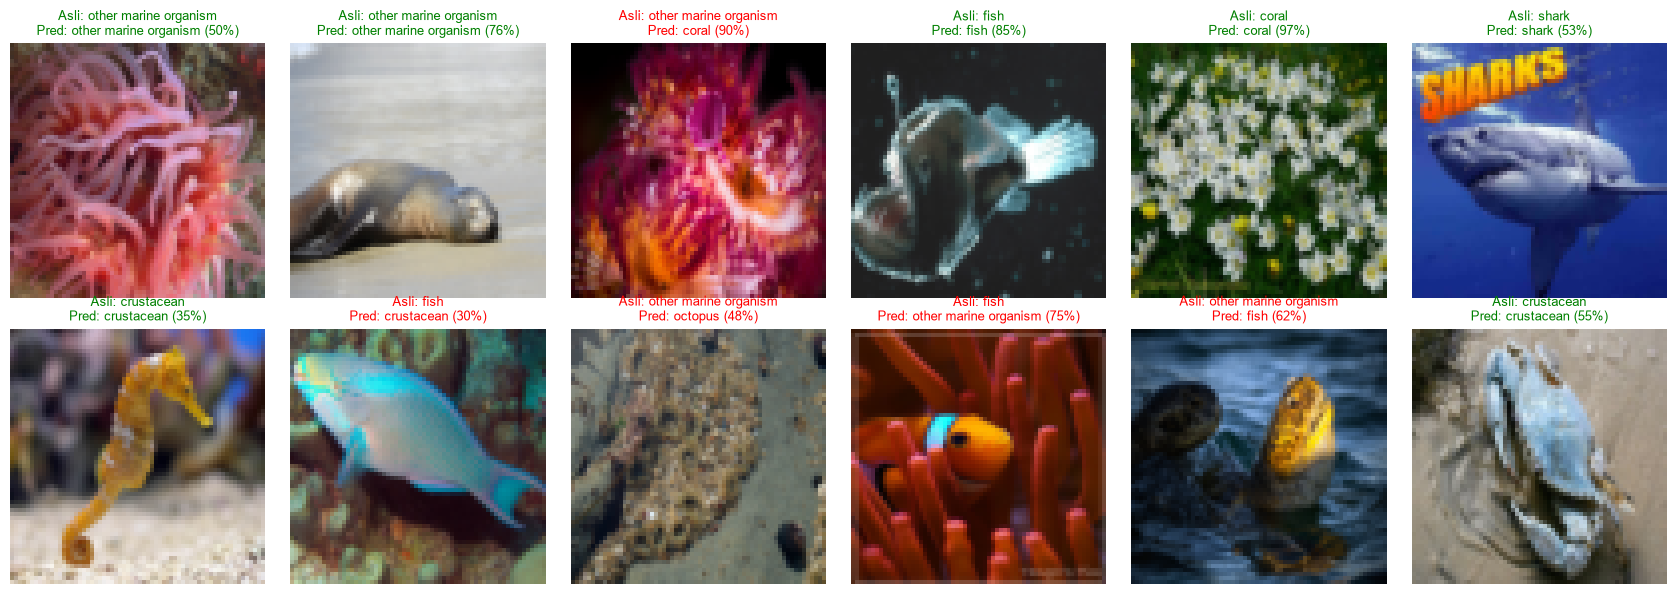

In [29]:
# 6.4 Contoh prediksi pada data uji (hijau = benar, merah = salah)
idx = np.random.RandomState(1).choice(len(X_val), 12, replace=False)
fig, axes = plt.subplots(2, 6, figsize=(17,6))
for a, i in zip(axes.ravel(), idx):
    a.imshow(X_val[i]); a.axis("off")
    ok = y_pred[i] == y_val[i]
    a.set_title(f"Asli: {class_names[y_val[i]]}\nPred: {class_names[y_pred[i]]} ({val_probs[i].max():.0%})",
                color="green" if ok else "red", fontsize=9)
plt.tight_layout(); plt.show()

In [30]:
dist_df = pd.DataFrame({
    "kelas": class_names,
    "total": [int((df["label"]==c).sum()) for c in class_names],
    "train": [int((train_df["label"]==c).sum()) for c in class_names],
    "val":   [int((val_df["label"]==c).sum()) for c in class_names],
})
dist_df.to_csv(f"{ARTIFACT_DIR}/class_distribution.csv", index=False)

with open(f"{ARTIFACT_DIR}/class_names.json", "w") as f: json.dump(class_names, f)
with open(f"{ARTIFACT_DIR}/history.json", "w") as f: json.dump({k:[float(v) for v in vs] for k, vs in hist.items()}, f)
with open(f"{ARTIFACT_DIR}/metrics.json", "w") as f:
    json.dump({"accuracy": acc, "macro": {"precision": p_m, "recall": r_m, "f1": f_m},
               "weighted": {"precision": p_w, "recall": r_w, "f1": f_w}, "report": report}, f)
with open(f"{ARTIFACT_DIR}/summary.json", "w") as f:
    json.dump({"n_images": int(len(df)), "n_classes": int(NUM_CLASSES), "n_train": int(len(train_df)),
               "n_val": int(len(val_df)), "img_size": IMG_SIZE, "imbalance_ratio": float(imb_ratio),
               "label_source": "pseudo-label CLIP zero-shot"}, f)
np.save(f"{ARTIFACT_DIR}/confusion_matrix.npy", cm)
print(os.listdir(ARTIFACT_DIR))

['cek_manual_100.csv', 'class_distribution.csv', 'class_names.json', 'confusion_matrix.npy', 'history.json', 'metrics.json', 'oceanic_cnn.keras', 'pseudo_labels.csv', 'summary.json']


## Langkah 7 — Dashboard Streamlit
Sel di bawah menulis `app.py` ke folder kerja notebook. Setiap grafik punya analisis otomatis dari hasil eksperimenmu, dan ada catatan bahwa label berasal dari pseudo-label.

In [ ]:
%%writefile app.py
import json
import numpy as np
import pandas as pd
import streamlit as st
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from PIL import Image

ART = "artifacts"
st.set_page_config(page_title="Klasifikasi Kehidupan Laut (CNN)", page_icon="🐠", layout="wide")

# ---------- Load artefak ----------
@st.cache_resource
def load_model():
    return tf.keras.models.load_model(f"{ART}/oceanic_cnn.keras")

@st.cache_data
def load_all():
    rd = lambda n: json.load(open(f"{ART}/{n}"))
    return (rd("class_names.json"), rd("history.json"), rd("metrics.json"), rd("summary.json"),
            np.load(f"{ART}/confusion_matrix.npy"), pd.read_csv(f"{ART}/class_distribution.csv"))

class_names, hist, metrics, summ, cm, dist = load_all()
model = load_model()
S = summ["img_size"]

def grad_cam(img_batch, layer_name="last_conv"):
    gm = tf.keras.Model(model.inputs, [model.get_layer(layer_name).output, model.output])
    with tf.GradientTape() as tape:
        conv_out, preds = gm(tf.convert_to_tensor(img_batch))
        cls = int(tf.argmax(preds[0]))
        score = preds[:, cls]
    grads = tape.gradient(score, conv_out)
    w = tf.reduce_mean(grads, axis=(0, 1, 2))
    heat = tf.nn.relu(tf.reduce_sum(conv_out[0] * w, axis=-1))
    heat = (heat / (tf.reduce_max(heat) + 1e-8)).numpy()
    return heat, preds[0].numpy()

def overlay(img, heat, alpha=0.45):
    h = tf.image.resize(heat[..., None], img.shape[:2]).numpy()[..., 0]
    return np.clip((1 - alpha) * img + alpha * plt.cm.jet(h)[..., :3], 0, 1)

# ---------- Header ----------
st.title("🐠 Klasifikasi Citra Kehidupan Laut dengan CNN")
st.markdown(
    "Dashboard ini menampilkan hasil eksperimen klasifikasi citra organisme laut "
    "(Oceanic Life Dataset, Kaggle) menggunakan **Convolutional Neural Network (CNN)**. "
    "Mulai dari ringkasan dataset, performa pelatihan, evaluasi model, hingga prediksi gambar baru secara langsung."
)

tab1, tab2, tab3, tab4, tab5 = st.tabs(
    ["📦 Dataset", "📈 Pelatihan", "🧮 Evaluasi", "🔥 Grad-CAM", "🔍 Prediksi Gambar Baru"])

# ---------- Tab 1: Dataset ----------
with tab1:
    st.subheader("Ringkasan Dataset")
    c1, c2, c3, c4 = st.columns(4)
    c1.metric("Jumlah kelas", summ["n_classes"])
    c2.metric("Total gambar", f"{summ['n_images']:,}")
    c3.metric("Data latih", f"{summ['n_train']:,}")
    c4.metric("Data uji", f"{summ['n_val']:,}")
    st.caption(f"Proporsi latih : uji = {summ['n_train']/summ['n_images']:.0%} : {summ['n_val']/summ['n_images']:.0%} "
               f"| Ukuran input model: {S}x{S} piksel RGB, piksel dinormalisasi 0-1.")

    if summ.get("label_source"):
        st.warning(f"Catatan: label kelas berasal dari {summ['label_source']}, bukan label manusia (ground truth). "
                   "Akurasi model mengukur kesesuaiannya dengan label tersebut.")

    st.subheader("Distribusi Data per Kelas")
    fig, ax = plt.subplots(figsize=(10, 4.5))
    sns.barplot(x="kelas", y="total", data=dist, palette="viridis", ax=ax)
    for i, v in enumerate(dist["total"]): ax.text(i, v, str(v), ha="center", va="bottom", fontsize=8)
    ax.set_xlabel("Kelas"); ax.set_ylabel("Jumlah gambar"); plt.xticks(rotation=40, ha="right")
    st.pyplot(fig)
    top, low = dist.loc[dist["total"].idxmax()], dist.loc[dist["total"].idxmin()]
    st.info(f"**Analisis:** kelas terbanyak adalah **{top['kelas']}** ({top['total']} gambar) dan tersedikit **{low['kelas']}** "
            f"({low['total']} gambar), rasio {summ['imbalance_ratio']:.2f}x. " +
            ("Data **tidak seimbang**, sehingga model berpotensi bias ke kelas mayoritas; "
             "karena itu dipakai class weight dan augmentasi." if summ["imbalance_ratio"] > 1.5
             else "Data relatif **seimbang**, sehingga risiko bias kelas mayoritas kecil."))
    st.dataframe(dist.rename(columns={"kelas": "Kelas", "total": "Total", "train": "Latih", "val": "Uji"}),
                 use_container_width=True, hide_index=True)

# ---------- Tab 2: Pelatihan ----------
with tab2:
    st.subheader("Grafik Akurasi dan Loss")
    ep = range(1, len(hist["loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(ep, hist["accuracy"], "o-", label="Train"); ax[0].plot(ep, hist["val_accuracy"], "o-", label="Validation")
    ax[0].set_title("Akurasi"); ax[0].set_xlabel("Epoch"); ax[0].legend()
    ax[1].plot(ep, hist["loss"], "o-", label="Train"); ax[1].plot(ep, hist["val_loss"], "o-", label="Validation")
    ax[1].set_title("Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
    st.pyplot(fig)
    best_ep = int(np.argmax(hist["val_accuracy"])) + 1
    gap = hist["accuracy"][-1] - hist["val_accuracy"][-1]
    st.info(f"**Analisis:** akurasi validasi tertinggi **{max(hist['val_accuracy']):.2%}** pada epoch **{best_ep}** "
            f"(total {len(hist['loss'])} epoch). Selisih akurasi train-validasi di akhir pelatihan {gap:.2%} -> " +
            ("terindikasi **overfitting** (model terlalu hafal data latih)." if gap > 0.1
             else "model **generalisasi dengan baik** dan kurva sudah cenderung konvergen."))

# ---------- Tab 3: Evaluasi ----------
with tab3:
    st.subheader("Hasil Evaluasi Model")
    m = metrics
    c1, c2, c3, c4 = st.columns(4)
    c1.metric("Accuracy", f"{m['accuracy']:.2%}")
    c2.metric("Precision (macro)", f"{m['macro']['precision']:.2%}")
    c3.metric("Recall (macro)", f"{m['macro']['recall']:.2%}")
    c4.metric("F1-Score (macro)", f"{m['macro']['f1']:.2%}")

    rep = pd.DataFrame(m["report"]).T.loc[class_names, ["precision", "recall", "f1-score", "support"]].round(4)
    st.dataframe(rep, use_container_width=True)
    best, worst = rep["f1-score"].idxmax(), rep["f1-score"].idxmin()
    st.info(f"**Analisis:** akurasi {m['accuracy']:.2%} menunjukkan proporsi prediksi benar secara keseluruhan. "
            f"F1 macro {m['macro']['f1']:.3f} (weighted {m['weighted']['f1']:.3f}) menggambarkan keseimbangan precision dan recall. "
            f"Kelas paling mudah dikenali: **{best}** (F1 {rep.loc[best,'f1-score']:.3f}); "
            f"paling sulit: **{worst}** (F1 {rep.loc[worst,'f1-score']:.3f}).")

    st.subheader("Confusion Matrix")
    cmn = cm / cm.sum(axis=1, keepdims=True)
    fig, ax = plt.subplots(1, 2, figsize=(17, 6.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=ax[0])
    ax[0].set_title("Jumlah")
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Greens", xticklabels=class_names, yticklabels=class_names, ax=ax[1])
    ax[1].set_title("Dinormalisasi per kelas asli")
    for a in ax: a.set_xlabel("Prediksi"); a.set_ylabel("Label asli"); a.tick_params(axis="x", rotation=40)
    st.pyplot(fig)
    off = cm.copy(); np.fill_diagonal(off, 0)
    i, j = np.unravel_index(off.argmax(), off.shape)
    st.info(f"**Analisis:** diagonal yang gelap berarti prediksi benar. Kesalahan terbanyak terjadi saat "
            f"**{class_names[i]}** diprediksi sebagai **{class_names[j]}** ({off[i, j]} gambar), "
            f"kemungkinan karena kemiripan visual (warna/bentuk/latar) kedua kelas.")

# ---------- Tab 4: Grad-CAM penjelasan ----------
with tab4:
    st.subheader("Feature Importance (Grad-CAM)")
    st.markdown(
        "Grad-CAM menyorot area gambar yang paling memengaruhi keputusan model. "
        "**Area merah/kuning** = pengaruh besar, **biru** = pengaruh kecil. "
        "Visualisasi ini dihitung langsung untuk gambar yang kamu unggah di tab **Prediksi Gambar Baru**."
    )
    st.info("**Analisis:** jika area merah berada pada objek (ikan, karang, dll.), model belajar dari fitur yang benar. "
            "Jika banyak berada di latar belakang (air/pasir), model mungkin mengandalkan konteks sehingga rawan salah pada gambar baru.")

# ---------- Tab 5: Prediksi ----------
with tab5:
    st.subheader("Upload Gambar untuk Prediksi")
    up = st.file_uploader("Pilih gambar (JPG/PNG/WEBP)", type=["jpg", "jpeg", "png", "webp", "bmp"])
    if up:
        img = Image.open(up).convert("RGB")
        arr = np.asarray(img.resize((S, S)), dtype="float32") / 255.0
        heat, probs = grad_cam(arr[None])
        k = int(probs.argmax())

        c1, c2 = st.columns(2)
        c1.image(img, caption="Gambar yang diunggah", use_container_width=True)
        c2.image(overlay(arr, heat), caption="Grad-CAM (area fokus model)", use_container_width=True)

        st.success(f"### Prediksi: **{class_names[k]}**  ({probs[k]:.2%})")
        prob_df = pd.DataFrame({"Kelas": class_names, "Probabilitas": probs}).sort_values("Probabilitas", ascending=False)
        st.bar_chart(prob_df.set_index("Kelas"))

        second = prob_df.iloc[1]
        msg = (f"**Analisis:** model memprediksi **{class_names[k]}** dengan keyakinan {probs[k]:.1%}. "
               f"Kandidat terdekat kedua: {second['Kelas']} ({second['Probabilitas']:.1%}). ")
        msg += ("Keyakinan rendah, gambar mungkin ambigu/berbeda dari data latih." if probs[k] < 0.6
                else "Keyakinan tinggi, ciri visual objek cukup jelas bagi model.")
        st.info(msg)
    else:
        st.write("Belum ada gambar. Unggah gambar organisme laut untuk melihat prediksi secara real-time.")

### Menjalankan Dashboard
Pastikan `app.py` dan folder `artifacts/` berada di folder yang sama. Jalankan di **terminal** (bukan di sel notebook):
```
pip install streamlit
streamlit run app.py
```
Browser akan terbuka di `http://localhost:8501`.

## Kesimpulan (isi sesuai hasil kamu)
- Dataset berisi **… gambar** tanpa label asli; label dibuat dengan **CLIP zero-shot** (estimasi akurasi label dari 100 sampel manual: **…%**).
- Model CNN mencapai akurasi **…%** dan F1-score macro **…** terhadap pseudo-label.
- Kelas paling mudah dikenali: **…**; paling sulit: **…** (kemungkinan penyebab: …).
- Grad-CAM menunjukkan model berfokus pada **… (objek / latar)**.
- Keterbatasan: label tidak 100% benar, sehingga performa nyata pada label manusia bisa lebih rendah.